+# Portfolio Optimization using Monte Carlo Simulation

A quantitative portfolio optimization project that uses historical market data to explore the **risk–return trade-off** across randomly generated portfolios.

### Objective
- Download historical prices for four Indian large-cap stocks.
- Calculate daily returns, annualized expected return, volatility, and Sharpe ratio.
- Generate 10,000 random long-only portfolios.
- Identify the **maximum-Sharpe portfolio** and **minimum-volatility portfolio**.
- Visualize the simulated opportunity set.

> **Note:** This is a historical simulation exercise, not investment advice. Results are sensitive to the selected stocks and lookback period.

## 1. Setup

The project uses:
- `yfinance` for historical market data
- `pandas` and `numpy` for data manipulation and portfolio mathematics
- `matplotlib` for visualization

In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

np.random.seed(42)  # Reproducible portfolio simulation

## 2. Download Historical Prices

The portfolio universe contains:
- Reliance Industries
- TCS
- Infosys
- HDFC Bank

The analysis uses approximately two years of historical daily closing prices.

In [3]:
tickers = ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS"]

prices = yf.download(
    tickers,
    period="2y",
    auto_adjust=True,
    progress=False
)["Close"]

prices = prices.dropna(how="all").dropna()

prices.head()

Ticker,HDFCBANK.NS,INFY.NS,RELIANCE.NS,TCS.NS
Date,,,,
2024-10-03,816.282959,1779.760620,1394.928467,3932.480957
2024-10-04,804.465759,1803.025146,1374.653564,3950.598145
2024-10-07,785.126465,1818.206055,1358.988892,3969.737061
2024-10-08,801.262756,1831.600586,1385.385864,3951.526611
2024-10-09,792.575867,1835.548584,1362.830688,3951.248535


## 3. Calculate Historical Returns

Daily percentage returns are used to estimate:
- Mean daily return
- Daily volatility
- Covariance between assets

The covariance matrix captures how the stocks move relative to one another and is central to portfolio risk calculation.

In [4]:
daily_returns = prices.pct_change().dropna()

mean_daily_returns = daily_returns.mean()
daily_volatility = daily_returns.std()
covariance_matrix = daily_returns.cov()

summary = pd.DataFrame({
    "Mean Daily Return": mean_daily_returns,
    "Daily Volatility": daily_volatility
})

summary

,Mean Daily Return,Daily Volatility
Ticker,,
HDFCBANK.NS,-0.000171,0.012416
INFY.NS,-0.000930,0.017634
RELIANCE.NS,-0.000272,0.012989
TCS.NS,-0.001158,0.015621


## 4. Portfolio Simulation

For each simulated portfolio:
1. Generate random positive weights.
2. Normalize the weights so they sum to 100%.
3. Calculate portfolio return using the weighted average of asset returns.
4. Calculate portfolio volatility using the covariance matrix.
5. Calculate the Sharpe ratio.

The simulation assumes a **long-only portfolio with no leverage or short selling**.

Annualization uses 252 trading days.

In [5]:
TRADING_DAYS = 252
N_PORTFOLIOS = 10_000
RISK_FREE_RATE = 0.07

results = []

for _ in range(N_PORTFOLIOS):
    weights = np.random.random(len(tickers))
    weights /= weights.sum()

    daily_return = np.dot(weights, mean_daily_returns)
    daily_vol = np.sqrt(weights.T @ covariance_matrix.values @ weights)

    annual_return = daily_return * TRADING_DAYS
    annual_volatility = daily_vol * np.sqrt(TRADING_DAYS)
    sharpe_ratio = (annual_return-RISK_FREE_RATE) / annual_volatility

    results.append([
        *weights,
        annual_return,
        annual_volatility,
        sharpe_ratio
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        *tickers,
        "annual_return",
        "annual_volatility",
        "sharpe_ratio"
    ]
)

results_df.head()

,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,annual_return,annual_volatility,sharpe_ratio
0,0.141022,0.357962,0.275610,0.225406,-0.174707,0.179586,-1.362619
1,0.126201,0.126181,0.046983,0.700635,-0.242752,0.210760,-1.483923
2,0.261391,0.307900,0.008951,0.421758,-0.207182,0.196134,-1.413232
3,0.590380,0.150594,0.128953,0.130073,-0.107585,0.160470,-1.106654
4,0.196011,0.338079,0.278284,0.187627,-0.161574,0.172605,-1.341642


## 5. Identify Optimal Portfolios

Two portfolios are highlighted:

### Maximum Sharpe Portfolio
The simulated portfolio with the highest return per unit of volatility.

### Minimum Volatility Portfolio
The simulated portfolio with the lowest estimated annualized volatility.

In [6]:
max_sharpe_port = results_df.loc[results_df["sharpe_ratio"].idxmax()]
min_vol_port = results_df.loc[results_df["annual_volatility"].idxmin()]

comparison = pd.DataFrame({
    "Maximum Sharpe": max_sharpe_port,
    "Minimum Volatility": min_vol_port
}).T

comparison

,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,annual_return,annual_volatility,sharpe_ratio
Maximum Sharpe,0.923909,0.020470,0.018671,0.036950,-0.056718,0.187053,-0.677442
Minimum Volatility,0.421855,0.068072,0.322731,0.187342,-0.110975,0.153911,-1.175842


## 6. Portfolio Weights

The optimized portfolios are represented by the simulated asset weights.

In [7]:
weight_comparison = pd.DataFrame({
    "Maximum Sharpe": max_sharpe_port[tickers],
    "Minimum Volatility": min_vol_port[tickers]
})

weight_comparison

,Maximum Sharpe,Minimum Volatility
RELIANCE.NS,0.923909,0.421855
TCS.NS,0.020470,0.068072
INFY.NS,0.018671,0.322731
HDFCBANK.NS,0.036950,0.187342


## 7. Efficient Frontier Approximation

The scatter plot shows the 10,000 simulated portfolios.

- **X-axis:** Annualized volatility
- **Y-axis:** Annualized expected return
- **Color:** Sharpe ratio
- ⭐ **Maximum Sharpe:** highest simulated Sharpe ratio
- ● **Minimum Volatility:** lowest simulated volatility

The simulation provides an approximation of the feasible risk–return opportunity set for the selected assets.

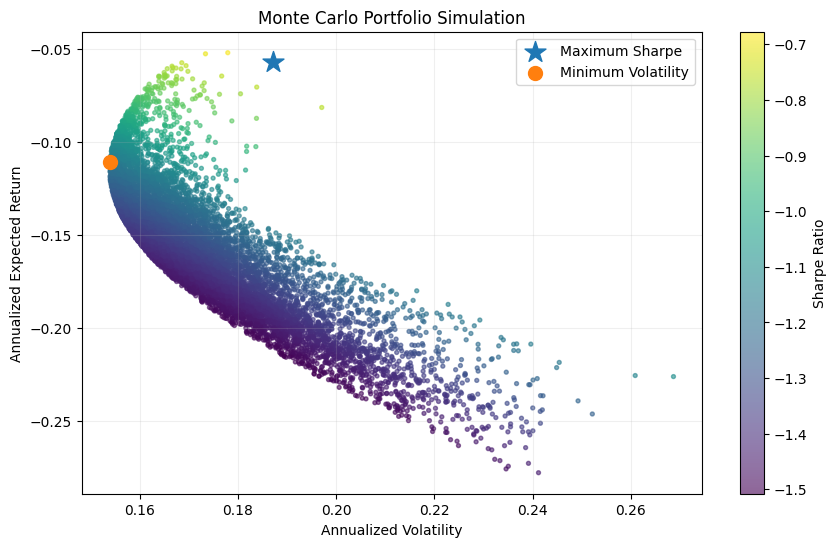

In [8]:
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    results_df["annual_volatility"],
    results_df["annual_return"],
    c=results_df["sharpe_ratio"],
    cmap="viridis",
    s=8,
    alpha=0.6
)

plt.scatter(
    max_sharpe_port["annual_volatility"],
    max_sharpe_port["annual_return"],
    marker="*",
    s=250,
    label="Maximum Sharpe"
)

plt.scatter(
    min_vol_port["annual_volatility"],
    min_vol_port["annual_return"],
    marker="o",
    s=100,
    label="Minimum Volatility"
)

plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Expected Return")
plt.title("Monte Carlo Portfolio Simulation")
plt.colorbar(scatter, label="Sharpe Ratio")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 8. Interpretation

This simulation demonstrates an important portfolio construction principle: **portfolio risk depends not only on the volatility of individual securities, but also on their covariance with one another.**

The maximum-Sharpe and minimum-volatility portfolios can therefore have substantially different allocations even when they use the same stock universe.

### Limitations
- Expected returns are estimated from historical averages.
- The covariance structure is assumed to remain relevant in the future.
- Only four securities are included.
- The simulation is long-only and does not include transaction costs, taxes, liquidity constraints, or a risk-free rate.
- The maximum-Sharpe result is the best portfolio **among the 10,000 simulated portfolios**, not necessarily the mathematically exact global optimum.

## 9. Possible Extensions

Potential next steps:
- Increase the asset universe.
- Compare equal-weighted and optimized portfolios.
- Add constraints such as maximum position size.
- Compare the optimized portfolios with NIFTY 50.
- Replace Monte Carlo search with numerical optimization.
- Conduct out-of-sample/backtesting analysis to test whether the historical optimization generalizes.